##Instalando uma biblioteca

Vamos instalar uma biblioteca necessária não disponível no Colab

In [1]:
%pip install importlib_resources
%pip install importlib_resources tensorflow-datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


##Importando as Bibliotecas

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow import data as tf_data
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import importlib_resources

#Carregando a base de dados

Vamos baixar a base de dados de gatos vs. cães usando TFDS (tensorflow datasets).

O aprendizado por transferência é mais útil ao trabalhar com conjuntos de dados muito pequenos. Para manter nosso conjunto de dados pequeno, usaremos 40% dos dados de treinamento originais para treinamento, 10% para validação e 10% para teste.

In [5]:
import tensorflow_datasets as tfds

tfds.disable_progress_bar()

train_ds, validation_ds, test_ds = tfds.load(
    "cats_vs_dogs",
    # Reserva 10% para validação e 10% para teste
    split=["train[:40%]", "train[40%:50%]", "train[50%:60%]"],
    as_supervised=True,  # Inclui rótulos
)

print(f"Number of training samples: {train_ds.cardinality()}")
print(f"Number of validation samples: {validation_ds.cardinality()}")
print(f"Number of test samples: {test_ds.cardinality()}")

SSLError: HTTPSConnectionPool(host='download.microsoft.com', port=443): Max retries exceeded with url: /download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Basic Constraints of CA cert not marked critical (_ssl.c:1081)')))

Estas são as primeiras 9 imagens no conjunto de dados de treinamento.
Observe que as imagens têm tamanhos diferentes.

In [4]:
plt.figure(figsize=(10, 10))
for i, (image, label) in enumerate(train_ds.take(9)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(int(label))
    plt.axis("off")

NameError: name 'train_ds' is not defined

<Figure size 1000x1000 with 0 Axes>

##Padronizando os dados

Nossas imagens brutas têm uma variedade de tamanhos, então vamos padronizar para um tamanho de imagem fixo. Escolhemos 150x150.


In [ ]:
resize_fn = keras.layers.Resizing(150, 150)

train_ds = train_ds.map(lambda x, y: (resize_fn(x), y))
validation_ds = validation_ds.map(lambda x, y: (resize_fn(x), y))
test_ds = test_ds.map(lambda x, y: (resize_fn(x), y))

##*Data Augmentation*

Quando não temos um grande conjunto de dados de imagens, é uma boa prática introduzir diversidade de amostras aplicando transformações aleatórias, porém realistas nas amostras da base de **treinamento**.

Isso ajuda a expor o modelo a diferentes aspectos dos dados de treinamento enquanto retarda o sobreajuste.   

Vamos aplicar inversão horizontal e pequenas rotações aleatórias.



In [ ]:
augmentation_layers = [layers.RandomFlip("horizontal"), layers.RandomRotation(0.1)]

def data_augmentation(x):
    for layer in augmentation_layers:
        x = layer(x)
    return x

train_ds = train_ds.map(lambda x, y: (data_augmentation(x), y))

Vamos agrupar os dados em lotes (batch) e usar a pré-busca para otimizar a velocidade de carregamento:

In [ ]:
batch_size = 64

train_ds = train_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()
validation_ds = validation_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()
test_ds = test_ds.batch(batch_size).prefetch(tf_data.AUTOTUNE).cache()

Vamos visualizar como fica a primeira imagem do primeiro lote após várias transformações aleatórias:

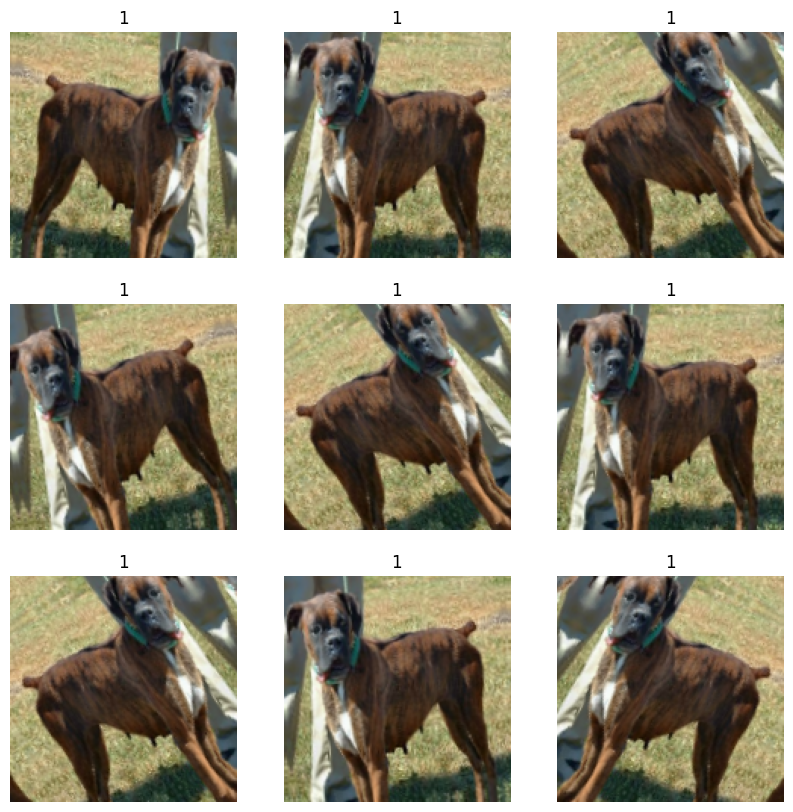

In [ ]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 10))
    first_image = images[0]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented_image = data_augmentation(np.expand_dims(first_image, 0))
        plt.imshow(np.array(augmented_image[0]).astype("int32"))
        plt.title(int(labels[0]))
        plt.axis("off")

#Construindo um modelo
Adicionamos uma camada Rescaling para dimensionar os valores de entrada (inicialmente no intervalo [0, 255]) para o intervalo [-1, 1].

Adicionamos uma camada Dropout antes da camada de classificação, para regularização.

Garantimos passar training=False ao chamar o modelo base, para que ele seja executado no modo de inferência, garantindo que as estatísticas de batchnorm não sejam atualizadas mesmo depois de descongelarmos o modelo base para ajuste fino.

In [ ]:
base_model = keras.applications.Xception(
    weights="imagenet",  # Carrega pesos pré-treinados no ImageNet.
    input_shape=(150, 150, 3),
    include_top=False,
)  # Não inclui o classificador ImageNet no topo.

# Congela o base_model
base_model.trainable = False

# Cria um novo modelo no topo
inputs = keras.Input(shape=(150, 150, 3))

# Os pesos pré-treinados do Xception exigem que a entrada seja dimensionada
# de (0, 255) para um intervalo de (-1., +1.), a camada de redimensionamento
# gera: `(inputs * scale) + offset`
scale_layer = keras.layers.Rescaling(scale=1 / 127.5, offset=-1)
x = scale_layer(inputs)

# O modelo base contém camadas batchnorm. Queremos mantê-las no modo de inferência
# quando descongelarmos o modelo base para ajuste fino, então garantimos que o
# base_model esteja rodando em modo de inferência aqui.
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)  # Regulariza com dropout
outputs = keras.layers.Dense(1)(x)
model = keras.Model(inputs, outputs)

model.summary(show_trainable=True)

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 150, 150, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ rescaling (Rescaling)       │ (None, 150, 150, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ xception (Functional)       │ (None, 5, 5, 2048)    │ 20,861,480 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 1)             │      2,049 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 20,863,529 (79.59 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

##Treinando a camada superior

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy()])

epochs = 5
print("Ajustando as camadas superiores do modelo (camada de classificação)")
history = model.fit(train_ds, epochs=epochs, validation_data=validation_ds)

Ajustando as camadas superiores do modelo (camada de classificação)
Epoch 1/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 115s 611ms/step - binary_accuracy: 0.9110 - loss: 0.1947 - val_binary_accuracy: 0.9703 - val_loss: 0.0868
Epoch 2/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - binary_accuracy: 0.9488 - loss: 0.1223 - val_binary_accuracy: 0.9699 - val_loss: 0.0794
Epoch 3/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - binary_accuracy: 0.9554 - loss: 0.1097 - val_binary_accuracy: 0.9712 - val_loss: 0.0776
Epoch 4/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 18s 126ms/step - binary_accuracy: 0.9577 - loss: 0.1019 - val_binary_accuracy: 0.9716 - val_loss: 0.0763
Epoch 5/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 18s 127ms/step - binary_accuracy: 0.9600 - loss: 0.0964 - val_binary_accuracy: 0.9712 - val_loss: 0.0771


##Fazendo uma rodada de fine tuning de todo o modelo
Finalmente, vamos descongelar o modelo base e treinar todo o modelo de ponta a ponta com uma taxa de aprendizado baixa.

É importante ressaltar que, embora o modelo base se torne treinável, ele ainda está rodando no modo de inferência, pois passamos training=False ao chamá-lo quando construímos o modelo. Isso significa que as camadas de normalização em lote (batch normalization) internas não atualizarão suas estatísticas de lote. Se o fizessem, causariam estragos nas representações aprendidas pelo modelo até agora.

In [ ]:
base_model.trainable = True
model.summary(show_trainable=True)

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),  # Taxa de aprendizado baixa
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy()],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

epochs = 5
print("Fitting the end-to-end model")
history_fine= model.fit(train_ds, epochs=epochs, validation_data=validation_ds)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 150, 150, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ rescaling (Rescaling)       │ (None, 150, 150, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ xception (Functional)       │ (None, 5, 5, 2048)    │ 20,861,480 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 1)             │      2,049 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 20,867,629 (79.60 MB)

 Trainable params: 20,809,001 (79.38 MB)

 Non-trainable params: 54,528 (213.00 KB)

 Optimizer params: 4,100 (16.02 KB)

Fitting the end-to-end model
Epoch 1/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 127s 577ms/step - binary_accuracy: 0.9675 - loss: 0.0818 - val_binary_accuracy: 0.9746 - val_loss: 0.0587
Epoch 2/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 59s 405ms/step - binary_accuracy: 0.9885 - loss: 0.0342 - val_binary_accuracy: 0.9746 - val_loss: 0.0608
Epoch 3/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 57s 391ms/step - binary_accuracy: 0.9960 - loss: 0.0146 - val_binary_accuracy: 0.9764 - val_loss: 0.0794
Epoch 4/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 58s 394ms/step - binary_accuracy: 0.9992 - loss: 0.0058 - val_binary_accuracy: 0.9776 - val_loss: 0.0794
Epoch 5/5
146/146 ━━━━━━━━━━━━━━━━━━━━ 58s 395ms/step - binary_accuracy: 0.9999 - loss: 0.0027 - val_binary_accuracy: 0.9794 - val_loss: 0.0806


#Avaliando o modelo


In [ ]:
print("Avaliação no conjunto de testes")
model.evaluate(test_ds)

Avaliação no conjunto de testes
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - binary_accuracy: 0.9759 - loss: 0.0938


[0.09376416355371475, 0.9759243130683899]

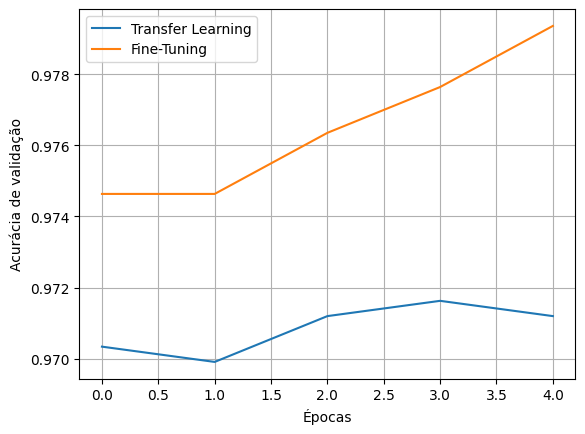

In [ ]:
plt.plot(history.history['val_binary_accuracy'], label='Transfer Learning')

plt.plot(history_fine.history['val_binary_accuracy'], label='Fine-Tuning')

plt.xlabel('Épocas')
plt.ylabel('Acurácia de validação')
plt.legend()
plt.grid()
plt.show()